In [1]:
%env CUDA_VISIBLE_DEVICES=1
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
import os
import torch
from ne_aligned_utils.plot import plot_aligned_embedding
import ot

from ne_aligned_utils.utils import compute_ot_plan, sparsify_plan, get_bipartite_graph
from openTSNE.affinity import Affinities

from openTSNE import TSNE

import scipy.sparse as sp

from mpl_toolkits.mplot3d import Axes3D

from ne_aligned_utils.plot import plot_aligned_embedding
from ne_aligned_utils.utils import sparsify_plan
from ne_aligned_utils.data import make_fig1_data

env: CUDA_VISIBLE_DEVICES=1


ModuleNotFoundError: No module named 'torch'

In [458]:
dataset = "fig1"

tol = 1e-12
maxIter = int(1e4)
res_path = os.path.join("/gpfs01/berens/user/sdamrich/data/ne_aligned", dataset)
fig_path = os.path.join("/gpfs01/berens/user/sdamrich/data/ne_aligned", "figures")


n0 = 1000
n1 = 5000
colors =  ["r"]*n0 + ["b"]*n1
seeds = [0, 1, 2, 3, 4]
eps_times_list = [1, 10, 100]
embd_dim = 2


Text(0.5, 0.98, 'Original data')

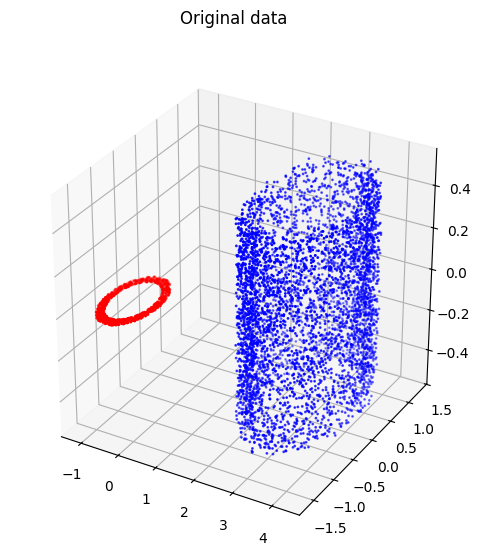

In [604]:
# show data
seed = 1
x0, x1 = make_fig1_data(n0=n0, n1=n1, seed=seed)
# plot in 3d
fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(*x0.T, c='r', s=1)
ax.scatter(*x1.T, c='b', s=1)
ax.set_box_aspect([1,1,1])  # Equal aspect ratio

fig.suptitle("Original data")

In [606]:
eps_times = 1

In [607]:
P = compute_ot_plan(x0, x1, eps_times=eps_times, tol=tol, maxIter=maxIter)

In [647]:
P.shape

(1000, 5000)

In [648]:
U, S, V = np.linalg.svd(P, full_matrices=False)

In [649]:
n0 = x0.shape[0]
n1 = x1.shape[0]

In [650]:
t = 0
eot0_embd = np.concatenate([U * S**t * np.sqrt(n0),
                       V.T *S**t * np.sqrt(n1)], axis=0)
t = 1
eot1_embd = np.concatenate([U * S**t * np.sqrt(n0),
                       V.T *S**t * np.sqrt(n1)], axis=0)

t = 0.5
eot_half_embd = np.concatenate([U * S**t * np.sqrt(n0),
                       V.T *S**t * np.sqrt(n1)], axis=0)

In [651]:
eot0_embd.shape

(6000, 1000)

In [652]:
S.shape

(1000,)

In [612]:
P_diag2 = eot0_embd @ np.diag(S) @ eot0_embd.T / np.sqrt(n0 * n1)

In [613]:
eot_half_embd.shape

(6000, 1000)

In [631]:
P_diag = eot_half_embd @ eot_half_embd.T / (np.sqrt(n0 * n1))

In [632]:
np.allclose(P_diag2, P_diag)

True

In [633]:
P_diag.shape

(6000, 6000)

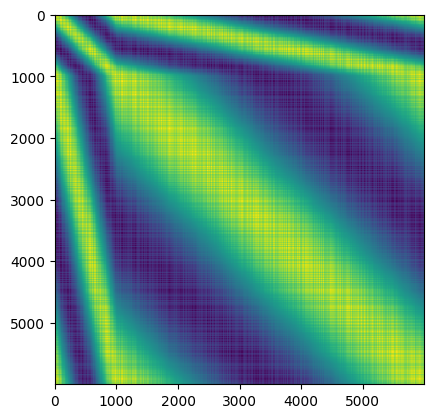

In [634]:
plt.imshow(P_diag, interpolation='none')

In [618]:
# some entries are neagtive
P_diag[P_diag <0] = 0

In [619]:
# avoid self-transport
np.fill_diagonal(P_diag, 0)

In [ ]:
# reweigh by size

In [522]:
1 / P_diag[:n0, :n0].sum(1)[0]

np.float64(5035.480980855713)

In [523]:
1 / P_diag[n0:, n0:].sum(1)[0]

np.float64(1001.4423689922831)

In [ ]:
# variants of the graph

In [524]:
reweigh = np.ones((n0+n1, n0+n1))
reweigh[:n0, :n0] = 1 / P_diag[:n0, :n0].sum(1) / n0
reweigh[n0:, n0:] = 1 / P_diag[n0:, n0:].sum(1) / n1

reweigh /= 4

In [525]:
P_diag_reweigh = reweigh * P_diag

In [526]:
P_diag_reweigh[:n0, :n0].sum()

np.float64(0.24999999999999997)

In [527]:
P_diag_reweigh[:n0, n0:].sum()

np.float64(0.2499999999999999)

In [528]:
P_diag_reweigh[n0:, :n0].sum()

np.float64(0.24999999999999956)

In [529]:
P_diag_reweigh[:n0, :n0].sum()

np.float64(0.24999999999999997)

In [530]:
P_diag_reweigh.sum()

np.float64(1.0000000000000007)

In [531]:
graph_eq = sp.csr_matrix(P_diag_reweigh)

In [642]:
graph_no_diag = get_bipartite_graph(P)
graph_no_diag /= graph_no_diag.sum()

In [533]:
graph = sp.csr_matrix(P_diag/ P_diag.sum())

In [643]:
init = np.random.randn(n0+n1, 2) * 0.0001

n_epochs = 200

In [644]:
n_early_epochs = n_epochs // 3
n_late_epochs = n_epochs - n_early_epochs
embedder = TSNE(n_components=embd_dim,
                verbose=True,
                random_state=0,
                early_exaggeration_iter=n_early_epochs,
                n_iter=n_late_epochs)

affinities = Affinities()
affinities.P = graph_no_diag.tocsr()

embd_no_diag = embedder.fit(affinities=affinities, initialization=init)

--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, early_exaggeration_iter=66, n_iter=134,
     random_state=0, verbose=True)
--------------------------------------------------------------------------------
===> Running optimization with exaggeration=12.00, lr=500.00 for 66 iterations...
Iteration   50, KL divergence -0.2693, 50 iterations in 12.6346 sec
   --> Time elapsed: 15.97 seconds
===> Running optimization with exaggeration=1.00, lr=6000.00 for 134 iterations...
Iteration   50, KL divergence 1.1973, 50 iterations in 13.4268 sec
Iteration  100, KL divergence 1.1970, 50 iterations in 11.0560 sec
   --> Time elapsed: 31.70 seconds


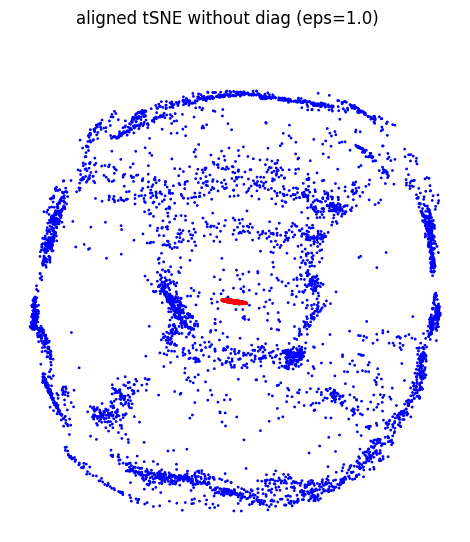

In [646]:
fig, ax = plt.subplots(figsize=(6, 6))

colors = ["r"] * n0 + ["b"] * n1

order = np.random.permutation(len(colors))
ax.scatter(*embd_no_diag[order].T, s=1, c=np.array(colors)[order])
ax.set_aspect('equal')
ax.axis("off")

fig.suptitle(f"aligned tSNE without diag (eps={1/eps_times})")
fig.savefig(os.path.join(fig_path, f"aligned_tsne_without_diag_eps_{eps_times}.png"))

In [537]:
n_early_epochs = n_epochs // 3
n_late_epochs = n_epochs - n_early_epochs
embedder = TSNE(n_components=embd_dim,
                verbose=True,
                random_state=0,
                early_exaggeration_iter=n_early_epochs,
                n_iter=n_late_epochs)

affinities = Affinities()
affinities.P = graph_eq.tocsr()

embd_eq = embedder.fit(affinities=affinities, initialization=init)

--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, early_exaggeration_iter=66, n_iter=134,
     random_state=0, verbose=True)
--------------------------------------------------------------------------------
===> Running optimization with exaggeration=12.00, lr=500.00 for 66 iterations...
Iteration   50, KL divergence 2.0639, 50 iterations in 19.9862 sec
   --> Time elapsed: 25.50 seconds
===> Running optimization with exaggeration=1.00, lr=6000.00 for 134 iterations...
Iteration   50, KL divergence 0.7081, 50 iterations in 17.7416 sec
Iteration  100, KL divergence 0.6842, 50 iterations in 17.2091 sec
   --> Time elapsed: 46.27 seconds


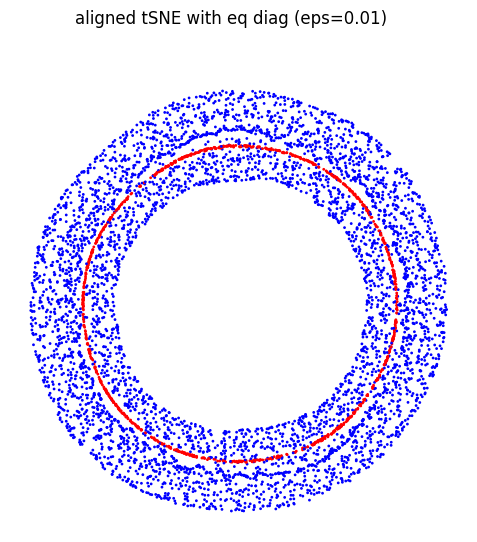

In [538]:
fig, ax = plt.subplots(figsize=(6, 6))

colors = ["r"] * n0 + ["b"] * n1

order = np.random.permutation(len(colors))
ax.scatter(*embd_eq[order].T, s=1, c=np.array(colors)[order])
ax.set_aspect('equal')
ax.axis("off")

fig.suptitle(f"aligned tSNE with eq diag (eps={1/eps_times})")
fig.savefig(os.path.join(fig_path, f"fig1_aligned_tsne_eq_diag_eps_{eps_times}.png"), dpi=300)

In [539]:
n_early_epochs = n_epochs // 3
n_late_epochs = n_epochs - n_early_epochs
embedder = TSNE(n_components=embd_dim,
                verbose=True,
                random_state=0,
                early_exaggeration_iter=n_early_epochs,
                n_iter=n_late_epochs)

affinities = Affinities()
affinities.P = graph.tocsr()

embd = embedder.fit(affinities=affinities, initialization=init)

--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, early_exaggeration_iter=66, n_iter=134,
     random_state=0, verbose=True)
--------------------------------------------------------------------------------
===> Running optimization with exaggeration=12.00, lr=500.00 for 66 iterations...
Iteration   50, KL divergence 1.4259, 50 iterations in 18.0416 sec
   --> Time elapsed: 23.31 seconds
===> Running optimization with exaggeration=1.00, lr=6000.00 for 134 iterations...
Iteration   50, KL divergence 0.3082, 50 iterations in 17.3487 sec
Iteration  100, KL divergence 0.1578, 50 iterations in 16.7215 sec
   --> Time elapsed: 44.84 seconds


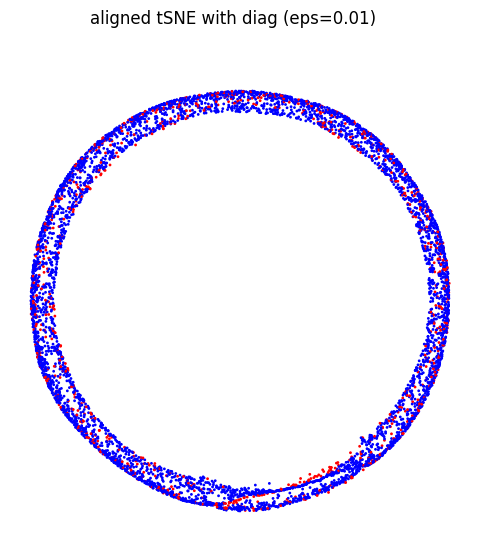

In [540]:
fig, ax = plt.subplots(figsize=(6, 6))

colors = ["r"] * n0 + ["b"] * n1

order = np.random.permutation(len(colors))
ax.scatter(*embd[order].T, s=1, c=np.array(colors)[order])
ax.set_aspect("equal")
ax.axis("off")

fig.suptitle(f"aligned tSNE with diag (eps={1/eps_times})")
fig.savefig(os.path.join(fig_path, f"fig1_aligned_tsne_diag_eps_{eps_times}.png"), dpi=300)

# Sparse

In [620]:
on
, k = 15

P_diag_sparse = np.zeros_like(P_diag)

P_diag_sparse[:n0, :n0][np.arange(n0,dtype=int)[:, None], P_diag[:n0, :n0].argsort(axis=1)[:, -k:]] = 1
P_diag_sparse[:n0, n0:][np.arange(n0,dtype=int)[:, None], P_diag[:n0, n0:].argsort(axis=1)[:, -int(k*n1/n0):]] = 1

P_diag_sparse[n0:, :n0][np.arange(n1,dtype=int)[:, None], P_diag[n0:, :n0].argsort(axis=1)[:, -k:]] = 1
P_diag_sparse[n0:, n0:][np.arange(n1,dtype=int)[:, None], P_diag[n0:, n0:].argsort(axis=1)[:, -int(k*n1/n0):]] = 1


In [621]:
P_diag_sparse.sum(1)

array([90., 90., 90., ..., 90., 90., 90.], shape=(6000,))

In [622]:
graph_diag_sparse = sp.csr_matrix(P_diag_sparse / P_diag_sparse.sum())
n_early_epochs = n_epochs // 3
n_late_epochs = n_epochs - n_early_epochs
embedder = TSNE(n_components=embd_dim,
                verbose=True,
                random_state=0,
                early_exaggeration_iter=n_early_epochs,
                n_iter=n_late_epochs)

affinities = Affinities()
affinities.P = graph_diag_sparse.tocsr()

embd_diag_sparse = embedder.fit(affinities=affinities, initialization=init)

--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, early_exaggeration_iter=66, n_iter=134,
     random_state=0, verbose=True)
--------------------------------------------------------------------------------
===> Running optimization with exaggeration=12.00, lr=500.00 for 66 iterations...
Iteration   50, KL divergence 3.3521, 50 iterations in 8.2474 sec
   --> Time elapsed: 10.58 seconds
===> Running optimization with exaggeration=1.00, lr=6000.00 for 134 iterations...
Iteration   50, KL divergence 2.2082, 50 iterations in 6.5369 sec
Iteration  100, KL divergence 2.2881, 50 iterations in 6.8445 sec
   --> Time elapsed: 17.91 seconds


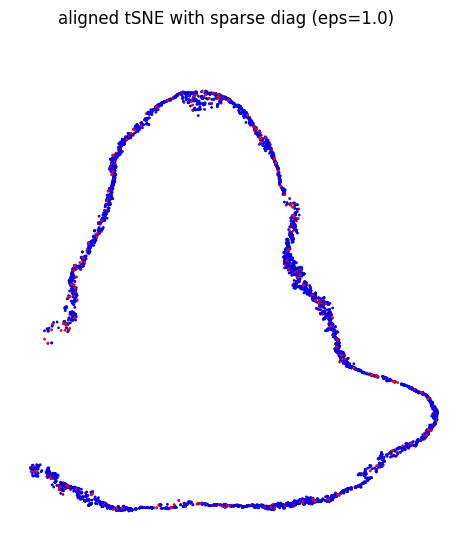

In [623]:
fig, ax = plt.subplots(figsize=(6, 6))

colors = ["r"] * n0 + ["b"] * n1

order = np.random.permutation(len(colors))
ax.scatter(*embd_diag_sparse[order].T, s=1, c=np.array(colors)[order])
ax.set_aspect("equal")
ax.axis("off")

fig.suptitle(f"aligned tSNE with sparse diag (eps={1/eps_times})")
fig.savefig(os.path.join(fig_path, f"fig1_aligned_tsne_sparse_diag_eps_{eps_times}.png"), dpi=300)

In [624]:
P_diag_sparse_sym = np.maximum(P_diag_sparse, P_diag_sparse.T)


In [639]:
P_diag_sparse_sym[:n0, :n0].sum()/ P_diag_sparse_sym[n0:, :n0].sum()

np.float64(0.1994805422205361)

In [640]:
P_diag_sparse_sym[n0:, n0:].sum()/ P_diag_sparse_sym[n0:, :n0].sum()


np.float64(4.985452263872879)

In [625]:
graph_diag_sparse_sym = sp.csr_matrix(P_diag_sparse_sym / P_diag_sparse_sym.sum())
n_early_epochs = n_epochs // 3
n_late_epochs = n_epochs - n_early_epochs
embedder = TSNE(n_components=embd_dim,
                verbose=True,
                random_state=0,
                early_exaggeration_iter=n_early_epochs,
                n_iter=n_late_epochs)

affinities = Affinities()
affinities.P = graph_diag_sparse_sym.tocsr()

embd_diag_sparse_sym = embedder.fit(affinities=affinities, initialization=init)

--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, early_exaggeration_iter=66, n_iter=134,
     random_state=0, verbose=True)
--------------------------------------------------------------------------------
===> Running optimization with exaggeration=12.00, lr=500.00 for 66 iterations...
Iteration   50, KL divergence 3.2933, 50 iterations in 10.5415 sec
   --> Time elapsed: 13.04 seconds
===> Running optimization with exaggeration=1.00, lr=6000.00 for 134 iterations...
Iteration   50, KL divergence 1.4445, 50 iterations in 7.0947 sec
Iteration  100, KL divergence 1.4379, 50 iterations in 7.1917 sec
   --> Time elapsed: 19.11 seconds


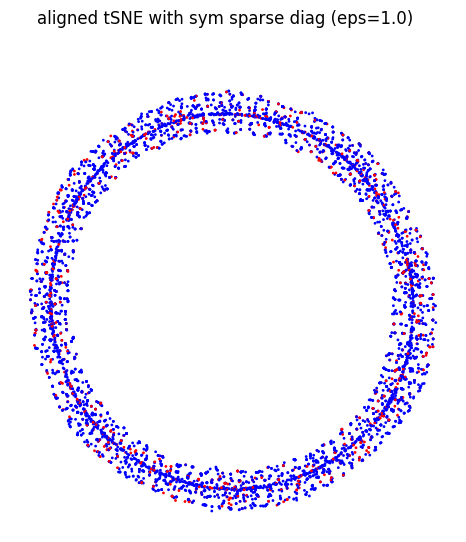

In [626]:
fig, ax = plt.subplots(figsize=(6, 6))

colors = ["r"] * n0 + ["b"] * n1

order = np.random.permutation(len(colors))
ax.scatter(*embd_diag_sparse_sym[order].T, s=1, c=np.array(colors)[order])
ax.set_aspect("equal")
ax.axis("off")

fig.suptitle(f"aligned tSNE with sym sparse diag (eps={1/eps_times})")
fig.savefig(os.path.join(fig_path, f"fig1_aligned_tsne_sym_sparse_diag_eps_{eps_times}.png"), dpi=300)

In [627]:
k = 15

P_diag_sparse_k = np.zeros_like(P_diag)

P_diag_sparse_k[:n0, :n0][np.arange(n0,dtype=int)[:, None], P_diag[:n0, :n0].argsort(axis=1)[:, -k:]] = 1
P_diag_sparse_k[:n0, n0:][np.arange(n0,dtype=int)[:, None], P_diag[:n0, n0:].argsort(axis=1)[:, -k:]] = 1

P_diag_sparse_k[n0:, :n0][np.arange(n1,dtype=int)[:, None], P_diag[n0:, :n0].argsort(axis=1)[:, -k:]] = 1
P_diag_sparse_k[n0:, n0:][np.arange(n1,dtype=int)[:, None], P_diag[n0:, n0:].argsort(axis=1)[:, -k:]] = 1
print(P_diag_sparse_k.sum(1))
P_diag_sparse_k_sym = np.maximum(P_diag_sparse_k, P_diag_sparse_k.T)


[30. 30. 30. ... 30. 30. 30.]


In [628]:
graph_diag_sparse_k_sym = sp.csr_matrix(P_diag_sparse_k_sym / P_diag_sparse_k_sym.sum())
n_early_epochs = n_epochs // 3
n_late_epochs = n_epochs - n_early_epochs
embedder = TSNE(n_components=embd_dim,
                verbose=True,
                random_state=0,
                early_exaggeration_iter=n_early_epochs,
                n_iter=n_late_epochs)

affinities = Affinities()
affinities.P = graph_diag_sparse_k_sym.tocsr()

embd_diag_sparse_k_sym = embedder.fit(affinities=affinities, initialization=init)

--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, early_exaggeration_iter=66, n_iter=134,
     random_state=0, verbose=True)
--------------------------------------------------------------------------------
===> Running optimization with exaggeration=12.00, lr=500.00 for 66 iterations...
Iteration   50, KL divergence 4.3300, 50 iterations in 15.3540 sec
   --> Time elapsed: 18.52 seconds
===> Running optimization with exaggeration=1.00, lr=6000.00 for 134 iterations...
Iteration   50, KL divergence 2.2643, 50 iterations in 7.6019 sec
Iteration  100, KL divergence 2.2080, 50 iterations in 6.6769 sec
   --> Time elapsed: 18.42 seconds


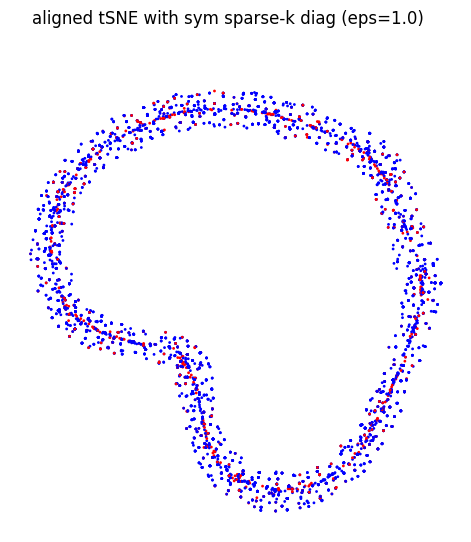

In [629]:
fig, ax = plt.subplots(figsize=(6, 6))

colors = ["r"] * n0 + ["b"] * n1

order = np.random.permutation(len(colors))
ax.scatter(*embd_diag_sparse_k_sym[order].T, s=1, c=np.array(colors)[order])
ax.set_aspect("equal")
ax.axis("off")

fig.suptitle(f"aligned tSNE with sym sparse-k diag (eps={1/eps_times})")
fig.savefig(os.path.join(fig_path, f"fig1_aligned_tsne_sym_sparse_k_diag_eps_{eps_times}.png"), dpi=300)